In [7]:
#Task 1
university = {
    "name": "FAST University",
    "children": [
        {"name": "CS Department", "children": [
            {"name": "Data Structures"},
            {"name": "Operating Systems"}
        ]},
        {"name": "EE Department", "children": [
            {"name": "Circuits"},
            {"name": "Signals"}
        ]}
    ]
}


In [8]:
#Task 2
tree = {
    "name": "Company",
    "children": [
        {"name": "HR"},
        {"name": "Tech", "children": [
            {"name": "Backend"},
            {"name": "Frontend"},
        ]}
    ]
}

def print_tree(node, level=0):
    print(" " * (level * 4) + node["name"])
    for child in node.get("children", []):
        print_tree(child, level + 1)

print_tree(tree)

Company
    HR
    Tech
        Backend
        Frontend


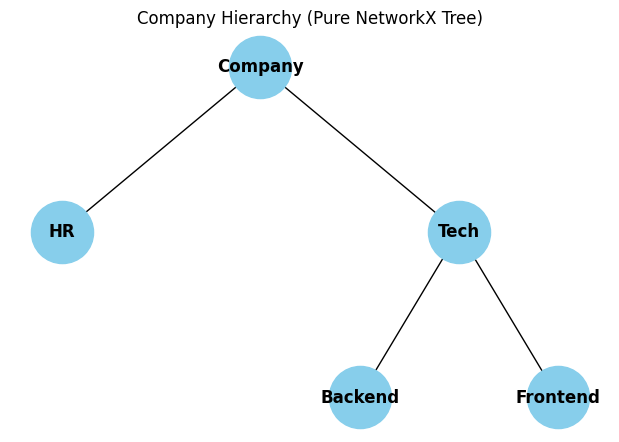

In [9]:
import matplotlib.pyplot as plt
import networkx as nx

tree = {
    "name": "Company",
    "children": [
        {"name": "HR"},
        {"name": "Tech", "children": [
            {"name": "Backend"},
            {"name": "Frontend"},
        ]}
    ]
}

G = nx.DiGraph()
def add_edges(G, node, parent=None):
    G.add_node(node["name"])
    if parent:
        G.add_edge(parent, node["name"])
    for child in node.get("children", []):
        add_edges(G, child, node["name"])

add_edges(G, tree)
def hierarchy_pos(G, root, width=1., vert_gap=0.2, xcenter=0.5, pos=None, level=0, parent=None):
    if pos is None:
        pos = {root: (xcenter, 1.0)}
    children = list(G.successors(root))
    if len(children) != 0:
        dx = width / len(children)
        nextx = xcenter - width/2 - dx/2
        for child in children:
            nextx += dx
            pos[child] = (nextx, 1.0 - vert_gap*(level+1))
            hierarchy_pos(G, child, width=dx, vert_gap=vert_gap, xcenter=nextx, pos=pos, level=level+1, parent=root)
    return pos

pos = hierarchy_pos(G, "Company")

plt.figure(figsize=(6,4))
nx.draw(G, pos, with_labels=True, node_size=2000, node_color="skyblue", arrows=False, font_weight="bold")
plt.title("Company Hierarchy (Pure NetworkX Tree)")
plt.show()


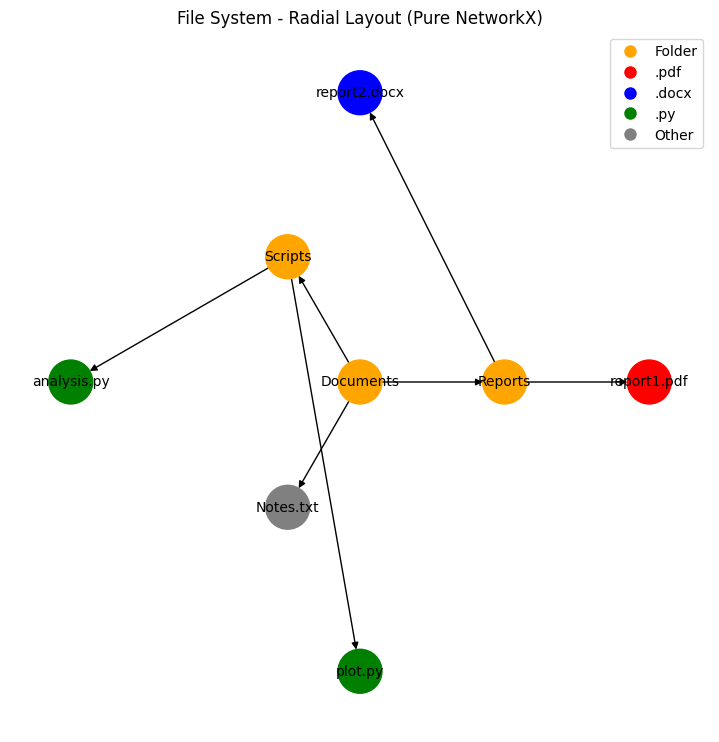

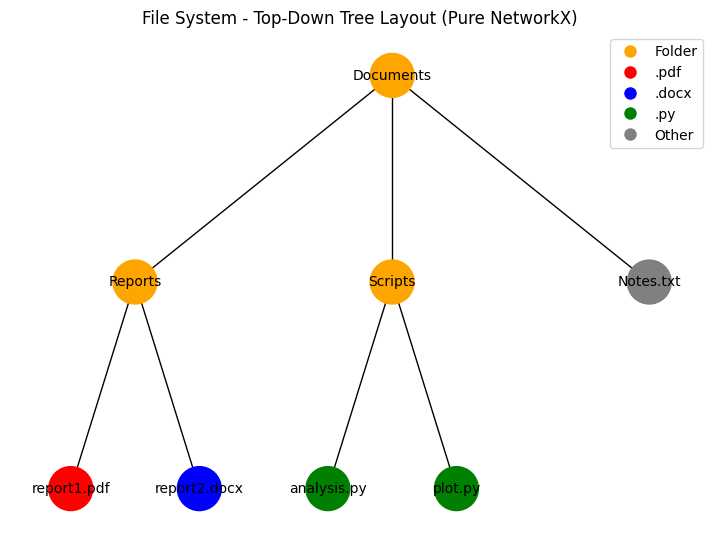

In [10]:
import networkx as nx
import matplotlib.pyplot as plt
import math
from matplotlib.lines import Line2D

# ----------------------------
# 1. Sample File System
# ----------------------------
filesystem = {
    "Documents": {
        "Reports": {
            "report1.pdf": None,
            "report2.docx": None
        },
        "Scripts": {
            "analysis.py": None,
            "plot.py": None
        },
        "Notes.txt": None
    }
}

# ----------------------------
# 2. Build Graph
# ----------------------------
G = nx.DiGraph()

def add_fs_edges(G, node, parent=None, fs_dict=filesystem):
    G.add_node(node)
    if parent:
        G.add_edge(parent, node)
    # get children
    children = fs_dict[node] if parent is None else fs_dict.get(node, {})
    if isinstance(children, dict):
        for child in children:
            add_fs_edges(G, child, node, children)

add_fs_edges(G, "Documents")

# ----------------------------
# 3. Assign colors by file type
# ----------------------------
color_map = {}
for node in G.nodes():
    if "." in node:
        ext = node.split(".")[-1]
        if ext == "pdf":
            color_map[node] = "red"
        elif ext == "docx":
            color_map[node] = "blue"
        elif ext == "py":
            color_map[node] = "green"
        else:
            color_map[node] = "gray"
    else:
        color_map[node] = "orange"  # folders

colors = [color_map[n] for n in G.nodes()]

legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Folder', markerfacecolor='orange', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='.pdf', markerfacecolor='red', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='.docx', markerfacecolor='blue', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='.py', markerfacecolor='green', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='Other', markerfacecolor='gray', markersize=10)
]

# ----------------------------
# 4. Pure NetworkX Radial Layout
# ----------------------------
def radial_layout(G, root, max_radius=1.0):
    levels = {}
    def assign_levels(node, depth=0):
        levels[node] = depth
        for child in G.successors(node):
            assign_levels(child, depth+1)
    assign_levels(root)

    max_depth = max(levels.values())
    nodes_by_level = [[] for _ in range(max_depth+1)]
    for node, depth in levels.items():
        nodes_by_level[depth].append(node)

    pos = {}
    for depth, nodes in enumerate(nodes_by_level):
        radius = max_radius * depth / max_depth if max_depth > 0 else 0
        n = len(nodes)
        for i, node in enumerate(nodes):
            angle = 2*math.pi*i/n if n>1 else 0
            x = radius * math.cos(angle)
            y = radius * math.sin(angle)
            pos[node] = (x, y)
    return pos

pos_radial = radial_layout(G, "Documents")

plt.figure(figsize=(7,7))
nx.draw(G, pos_radial, with_labels=True, node_color=colors, node_size=1000, font_size=10)
plt.title("File System - Radial Layout (Pure NetworkX)")
plt.legend(handles=legend_elements, loc='upper right')
plt.show()

# ----------------------------
# 5. Pure NetworkX Top-Down Layout
# ----------------------------
def hierarchy_pos(G, root, width=1., vert_gap=0.2, xcenter=0.5, pos=None, level=0):
    if pos is None:
        pos = {root: (xcenter, 1.0)}
    children = list(G.successors(root))
    if len(children) != 0:
        dx = width / len(children)
        nextx = xcenter - width/2 - dx/2
        for child in children:
            nextx += dx
            pos[child] = (nextx, 1.0 - vert_gap*(level+1))
            hierarchy_pos(G, child, width=dx, vert_gap=vert_gap, xcenter=nextx, pos=pos, level=level+1)
    return pos

pos_tree = hierarchy_pos(G, "Documents")

plt.figure(figsize=(7,5))
nx.draw(G, pos_tree, with_labels=True, node_color=colors, node_size=1000, font_size=10, arrows=False)
plt.title("File System - Top-Down Tree Layout (Pure NetworkX)")
plt.legend(handles=legend_elements, loc='upper right')
plt.show()


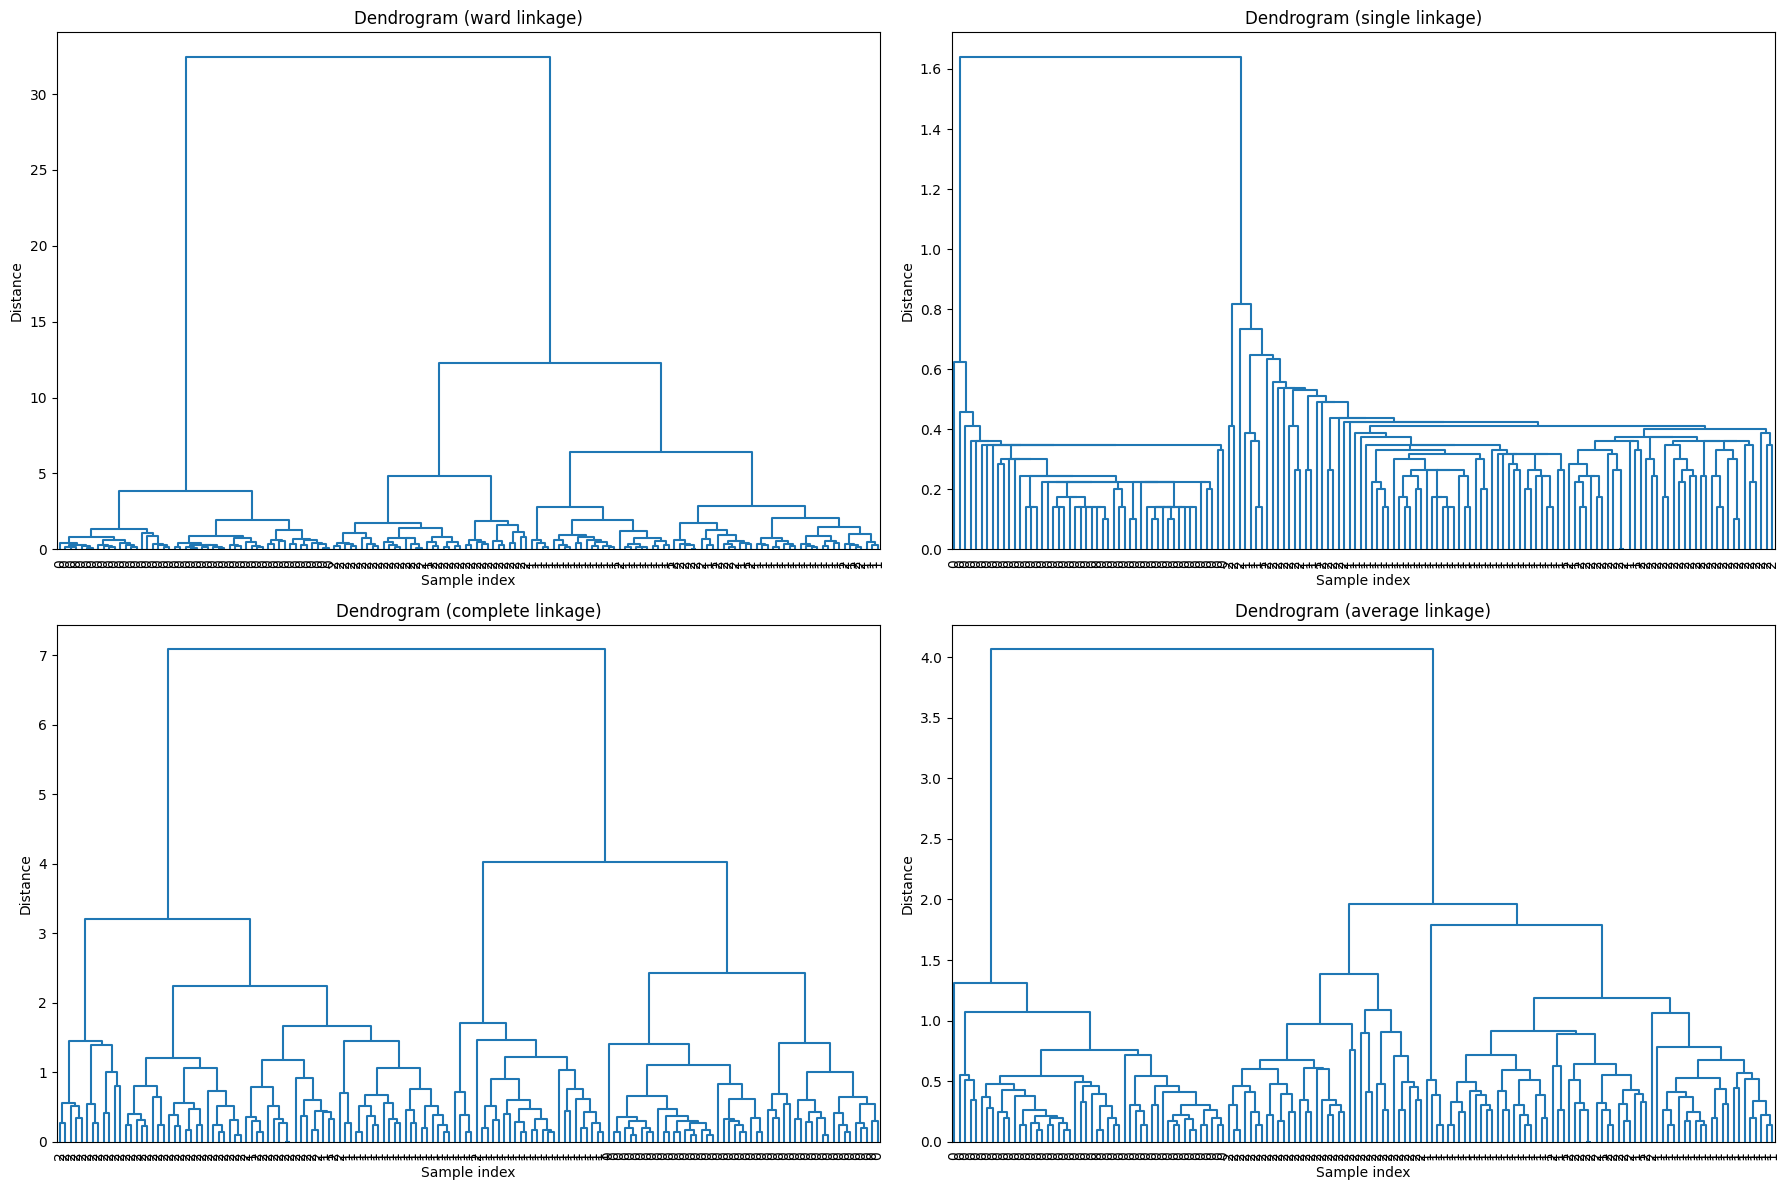

In [11]:
# Full Iris hierarchical clustering and dendrogram comparison
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
import pandas as pd

# Load Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Linkage methods to compare
methods = ['ward', 'single', 'complete', 'average']

plt.figure(figsize=(18, 12))

for i, method in enumerate(methods):
    linked = linkage(X, method=method)
    plt.subplot(2, 2, i+1)
    dendrogram(
        linked,
        labels=y,
        leaf_rotation=90,
        leaf_font_size=10,
        color_threshold=0,  # optional: no automatic coloring of clusters
    )
    plt.title(f'Dendrogram ({method} linkage)')
    plt.xlabel('Sample index')
    plt.ylabel('Distance')

plt.tight_layout()
plt.show()


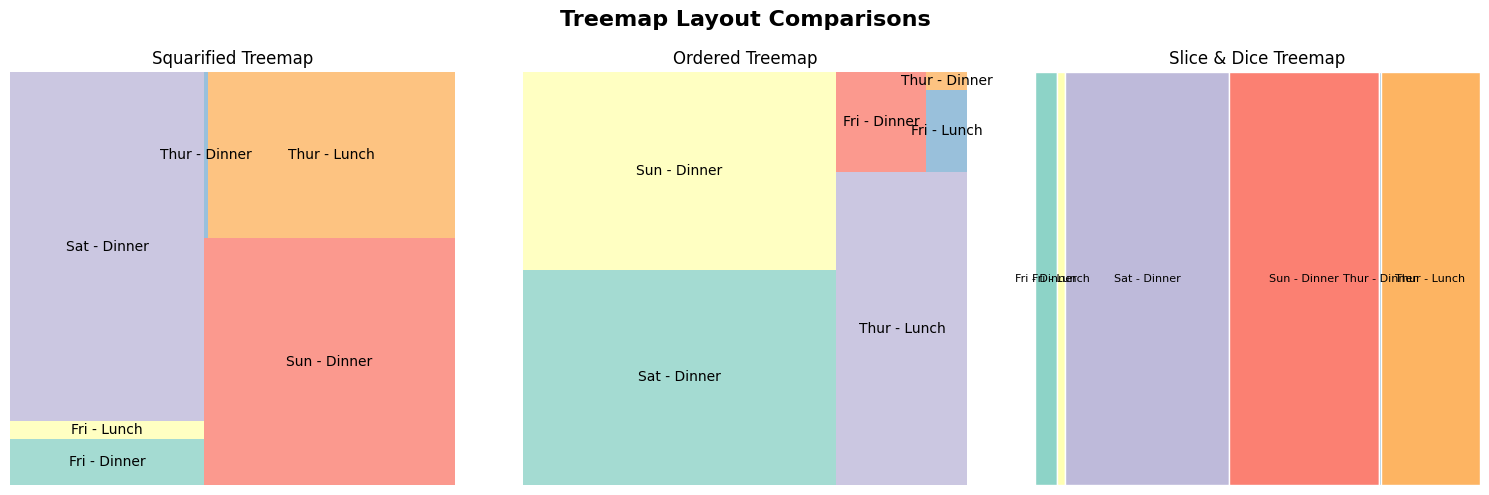

In [ ]:
import matplotlib.pyplot as plt
import squarify
import pandas as pd

# Load dataset
df = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv")

# Aggregate total bills by day and time
agg = df.groupby(['day', 'time'], as_index=False)['total_bill'].sum()

# Prepare data
values = agg['total_bill'].tolist()
labels = [f"{d} - {t}" for d, t in zip(agg['day'], agg['time'])]
colors = list(plt.cm.Set3.colors) * 3  # extend color palette

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("Treemap Layout Comparisons", fontsize=16, fontweight='bold')

# --- 1. Squarified Treemap (default layout) ---
squarify.plot(sizes=values, label=labels, color=colors, alpha=0.8, ax=axes[0])
axes[0].set_title("Squarified Treemap")
axes[0].axis("off")

# --- 2. Ordered Treemap (sorted by total_bill) ---
ordered = agg.sort_values(by='total_bill', ascending=False)
ordered_labels = [f"{d} - {t}" for d, t in zip(ordered['day'], ordered['time'])]
squarify.plot(sizes=ordered['total_bill'], label=ordered_labels, color=colors, alpha=0.8, ax=axes[1])
axes[1].set_title("Ordered Treemap")
axes[1].axis("off")

# --- 3. Slice & Dice Treemap (recursive layout) ---
def slice_dice(ax, x, y, width, height, values, labels, colors, horizontal=True):
    total = sum(values)
    start = 0
    for i, v in enumerate(values):
        frac = v / total
        if horizontal:
            w = width * frac
            h = height
            ax.add_patch(plt.Rectangle((x + start, y), w, h, color=colors[i % len(colors)], ec='white'))
            ax.text(x + start + w/2, y + h/2, labels[i], ha='center', va='center', fontsize=8)
            start += w
        else:
            w = width
            h = height * frac
            ax.add_patch(plt.Rectangle((x, y + start), w, h, color=colors[i % len(colors)], ec='white'))
            ax.text(x + w/2, y + start + h/2, labels[i], ha='center', va='center', fontsize=8)
            start += h

# call layout
slice_dice(axes[2], 0, 0, 1, 1, values, labels, colors, horizontal=True)
axes[2].set_xlim(0, 1)
axes[2].set_ylim(0, 1)
axes[2].axis("off")
axes[2].set_title("Slice & Dice Treemap")

plt.tight_layout()
plt.show()


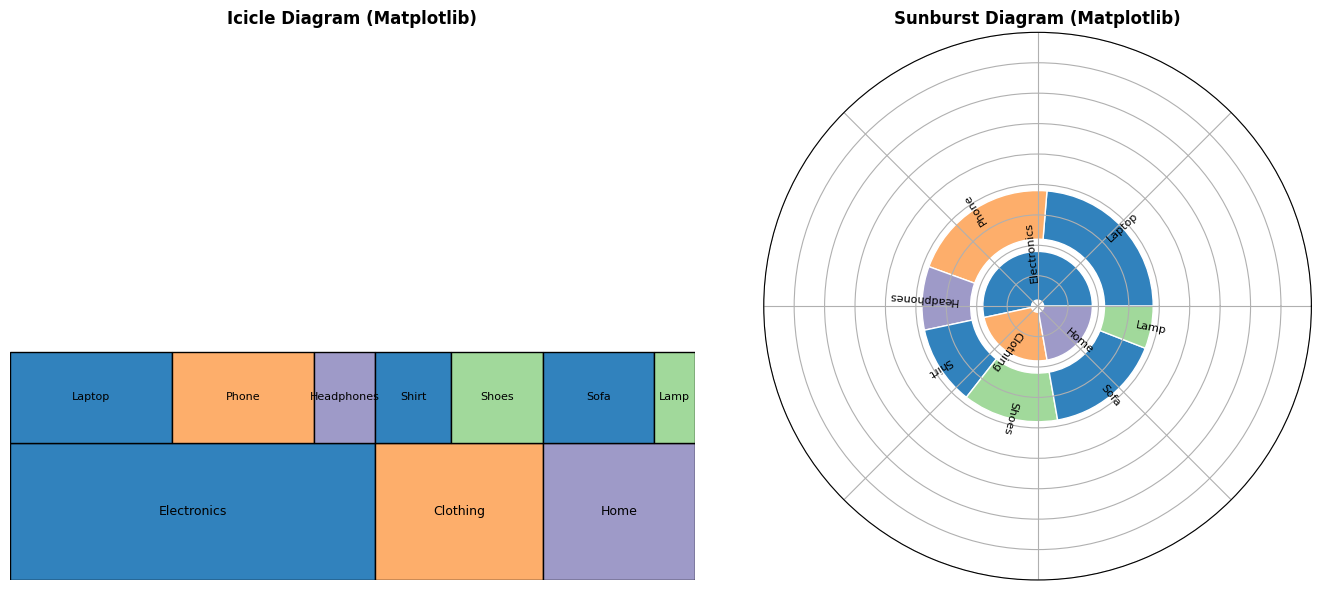

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ----------------------------------------
# Hierarchical Data: Category → Product → Sales
# ----------------------------------------
hierarchy = {
    'Electronics': {'Laptop': 32000, 'Phone': 28000, 'Headphones': 12000},
    'Clothing': {'Shirt': 15000, 'Shoes': 18000},
    'Home': {'Sofa': 22000, 'Lamp': 8000}
}


def plot_icicle(ax, hierarchy, x=0, y=0, width=1, height=1, level=0, cmap=plt.cm.tab20c):
    """Recursively draw hierarchical rectangles."""
    categories = list(hierarchy.keys())
    total = sum(sum(v.values()) if isinstance(v, dict) else v for v in hierarchy.values())
    offset = 0
    bar_height = 1 / (level + 2)

    for i, key in enumerate(categories):
        val = hierarchy[key]
        if isinstance(val, dict):
            subtotal = sum(val.values())
            w = width * (subtotal / total)
            ax.add_patch(plt.Rectangle((x + offset, y), w, bar_height,
                                       facecolor=cmap(i / len(categories)), edgecolor='black'))
            ax.text(x + offset + w / 2, y + bar_height / 2, key, ha='center', va='center', fontsize=9)
            plot_icicle(ax, val, x + offset, y + bar_height, w, height, level + 1, cmap)
            offset += w
        else:
            w = width * (val / total)
            ax.add_patch(plt.Rectangle((x + offset, y), w, bar_height,
                                       facecolor=cmap(i / len(categories)), edgecolor='black'))
            ax.text(x + offset + w / 2, y + bar_height / 2, key, ha='center', va='center', fontsize=8)
            offset += w


def plot_sunburst(ax, hierarchy, start_angle=0, total=None, level=0, cmap=plt.cm.tab20c):
    """Recursively draw concentric wedges."""
    if total is None:
        total = sum(sum(v.values()) if isinstance(v, dict) else v for v in hierarchy.values())

    offset = start_angle
    categories = list(hierarchy.keys())

    for i, key in enumerate(categories):
        val = hierarchy[key]
        if isinstance(val, dict):
            subtotal = sum(val.values())
            theta1 = offset
            theta2 = offset + 2 * np.pi * subtotal / total
            ax.barh(level, width=theta2 - theta1, left=theta1, height=0.8,
                    color=cmap(i / len(categories)), edgecolor='white')
            ax.text((theta1 + theta2) / 2, level + 0.4, key,
                    rotation=np.degrees((theta1 + theta2) / 2),
                    ha='center', va='center', fontsize=8)
            plot_sunburst(ax, val, start_angle=theta1, total=total, level=level + 1, cmap=cmap)
            offset = theta2
        else:
            theta1 = offset
            theta2 = offset + 2 * np.pi * val / total
            ax.barh(level, width=theta2 - theta1, left=theta1, height=0.8,
                    color=cmap(i / len(categories)), edgecolor='white')
            ax.text((theta1 + theta2) / 2, level + 0.4, key,
                    rotation=np.degrees((theta1 + theta2) / 2),
                    ha='center', va='center', fontsize=8)
            offset = theta2

fig = plt.figure(figsize=(14, 6))

# Icicle
ax1 = fig.add_subplot(1, 2, 1)
plot_icicle(ax1, hierarchy)
ax1.set_xlim(0, 1)
ax1.set_ylim(0, 2)
ax1.axis('off')
ax1.set_title("Icicle Diagram (Matplotlib)", fontsize=12, fontweight='bold')

# Sunburst
ax2 = fig.add_subplot(1, 2, 2, polar=True)
plot_sunburst(ax2, hierarchy)
ax2.set_ylim(-0.5, 4)
ax2.set_yticklabels([])
ax2.set_xticklabels([])
ax2.set_title("Sunburst Diagram (Matplotlib)", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()
